# 02 — Data Preparation & Feature Engineering
**Workforce Pulse · Phase 2**

**Objective.** Turn the validated raw extract into two analytical datasets:

| File | Content | Used by |
|---|---|---|
| `data/processed/hr_cleaned.csv` | Raw columns minus constants, trimmed text, binary flags | SQL (Phase 3), audit |
| `data/processed/hr_featured.csv` | Cleaned + engineered business features | EDA, Power BI, modelling |

All logic lives in `src/features.py` so the notebook, the model pipeline and any future refresh use **the same code**.

**Leakage rule.** Row-wise features (bands, flags, indices) only use the employee's own record → safe to compute on
the full dataset. The peer-referenced salary ratio uses *other* employees → computed on the full data here for
**descriptive** use only; the model learns it from the training split inside the pipeline (`PeerSalaryRatio`).

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

from src.features import (clean, add_row_features, add_peer_salary_ratio, CONSTANT_COLS,
                          UNDOCUMENTED_RATE_COLS, SATISFACTION_ITEMS, MODEL_NUMERIC, MODEL_CATEGORICAL)
from src.data_dictionary import PROTECTED, ID_COL

raw = pd.read_csv(DATA / "raw" / "WA_Fn-UseC_-HR-Employee-Attrition.csv", encoding="utf-8-sig")
raw.shape

(1470, 35)

## 1. Cleaning
Phase 1 found no missing values, duplicates or invalid codes, so cleaning is deliberately light. We still apply each
step **defensively** so a future extract with problems would be handled by the same code.

| Step | Why |
|---|---|
| Trim text values | Protects joins / group-bys from `"Sales "` vs `"Sales"` |
| Drop `EmployeeCount`, `Over18`, `StandardHours` | Constant (Phase 1 evidence) |
| Drop exact duplicates | Defensive (0 found) |
| `AttritionFlag` = 1 if Attrition = Yes | Numeric target for SQL sums and models |
| `OvertimeFlag` = 1 if OverTime = Yes | Numeric indicator for KPIs |

In [2]:
cleaned = clean(raw)
print("Shape before:", raw.shape, "-> after:", cleaned.shape)
print("Dropped columns:", sorted(set(raw.columns) - set(cleaned.columns)))
print("Added columns:  ", sorted(set(cleaned.columns) - set(raw.columns)))

Shape before: (1470, 35) -> after: (1470, 34)
Dropped columns: ['EmployeeCount', 'Over18', 'StandardHours']
Added columns:   ['AttritionFlag', 'OvertimeFlag']


In [3]:
# Validation: flags must agree exactly with their source columns
assert (cleaned.AttritionFlag == (cleaned.Attrition == "Yes")).all()
assert (cleaned.OvertimeFlag == (cleaned.OverTime == "Yes")).all()
assert cleaned[ID_COL].is_unique and cleaned.isna().sum().sum() == 0
print("Attrition count:", cleaned.AttritionFlag.sum(), "| Overtime count:", cleaned.OvertimeFlag.sum())

Attrition count: 237 | Overtime count: 416


## 2. Feature engineering
Each feature answers a business question from `docs/business_requirements.md`. Full definitions are in
`docs/feature_dictionary.md`.

### A. Tenure band — *Where in the employee lifecycle does attrition concentrate?*
### B. Age band — *EDA and fairness audit only, never a model feature*
### C. Income band — *Management-friendly salary slabs for reporting*
### D. Satisfaction index — *One experience score for dashboards*
The four items (Job, Environment, Relationship satisfaction, Work-life balance) are all 1–4 scales, so they are already
comparable; we average them and rescale to 0–1. **Equal weighting is a design assumption**, not a validated instrument.
`LowSatisfactionCount` counts how many of the four items are at the lowest level (1).
### E. Career progression — *Are people stuck?*
`RoleShareOfTenure` = YearsInCurrentRole / YearsAtCompany (defined as 1.0 when tenure is 0, i.e. first role).
`YearsSincePromotionBand` groups promotion gaps into 0–1, 2–4, 5+ years.
### F. Salary relative to JobLevel peers — *Is the employee paid below comparable colleagues?*
We compare with the **median of the same JobLevel**, not the department average: Phase 1 showed JobLevel and income
are almost the same signal (ρ = 0.92), so a department average mostly measures seniority mix. A ratio of 0.8 means
"earns 20 % less than the typical employee at the same level". Median is used because income is right-skewed.

In [4]:
featured = add_peer_salary_ratio(add_row_features(cleaned))
new_cols = [c for c in featured.columns if c not in cleaned.columns]
featured[new_cols].head()

,TenureBand,AgeBand,IncomeBand,SatisfactionIndex,LowSatisfactionCount,RoleShareOfTenure,YearsSincePromotionBand,JobLevelMedianIncome,SalaryRatioToLevel
0,Mid (6-10y),35-44,5k-10k,0.3333,2,0.6667,0-1y,5340.0,1.1223
1,Mid (6-10y),45-54,5k-10k,0.6667,0,0.7000,0-1y,5340.0,0.9607
2,New (0-2y),35-44,<5k,0.6667,0,1.0000,0-1y,2670.0,0.7828
3,Mid (6-10y),25-34,<5k,0.7500,0,0.8750,2-4y,2670.0,1.0895
4,New (0-2y),25-34,<5k,0.5000,1,1.0000,2-4y,2670.0,1.2989


## 3. Validate engineered features

In [5]:
# Bands must cover every employee (no NaN from pd.cut edges)
for c in ["TenureBand", "AgeBand", "IncomeBand", "YearsSincePromotionBand"]:
    assert featured[c].notna().all(), c
    print(f"{c:24s}", featured[c].value_counts(sort=False).to_dict())

TenureBand               {'New (0-2y)': 342, 'Early (3-5y)': 434, 'Mid (6-10y)': 448, 'Long (11y+)': 246}
AgeBand                  {'Under 25': 97, '25-34': 554, '35-44': 505, '45-54': 245, '55+': 69}
IncomeBand               {'<5k': 749, '5k-10k': 440, '10k-15k': 148, '15k+': 133}
YearsSincePromotionBand  {'0-1y': 938, '2-4y': 272, '5y+': 260}


In [6]:
# Bands must agree with their source ranges
chk = featured.groupby("TenureBand", observed=True)["YearsAtCompany"].agg(["min", "max", "count"])
display(chk)
featured.groupby("IncomeBand", observed=True)["MonthlyIncome"].agg(["min", "max", "count"])

,min,max,count
TenureBand,,,
New (0-2y),0,2,342
Early (3-5y),3,5,434
Mid (6-10y),6,10,448
Long (11y+),11,40,246


,min,max,count
IncomeBand,,,
<5k,1009,4999,749
5k-10k,5003,9998,440
10k-15k,10008,14852,148
15k+,15202,19999,133


In [7]:
# Index ranges
desc = featured[["SatisfactionIndex", "LowSatisfactionCount", "RoleShareOfTenure", "SalaryRatioToLevel"]].describe().T
assert featured.SatisfactionIndex.between(0, 1).all()
assert featured.RoleShareOfTenure.between(0, 1).all()
desc

,count,mean,std,min,25%,50%,75%,max
SatisfactionIndex,1470.0,0.576985,0.168604,0.0000,0.50,0.5833,0.6667,1.0000
LowSatisfactionCount,1470.0,0.631973,0.731429,0.0000,0.00,1.0000,1.0000,4.0000
RoleShareOfTenure,1470.0,0.608156,0.323450,0.0000,0.40,0.6667,0.8750,1.0000
SalaryRatioToLevel,1470.0,1.021795,0.246583,0.3779,0.86,1.0000,1.1221,1.8723


In [8]:
# Peer medians used (descriptive version, full dataset)
featured.groupby("JobLevel")["MonthlyIncome"].agg(n="count", median="median", min="min", max="max")

,n,median,min,max
JobLevel,,,,
1,543,2670.0,1009,4968
2,534,5340.0,2042,9998
3,218,9980.0,5210,13757
4,106,16154.0,11103,17924
5,69,19232.0,18041,19999


In [9]:
# Does the salary ratio add information beyond JobLevel / MonthlyIncome? (low correlation with JobLevel = good)
featured[["SalaryRatioToLevel", "MonthlyIncome", "JobLevel", "TotalWorkingYears", "Age"]].corr(method="spearman").round(2)

,SalaryRatioToLevel,MonthlyIncome,JobLevel,TotalWorkingYears,Age
SalaryRatioToLevel,1.00,0.31,-0.06,0.06,0.04
MonthlyIncome,0.31,1.00,0.92,0.71,0.47
JobLevel,-0.06,0.92,1.00,0.73,0.49
TotalWorkingYears,0.06,0.71,0.73,1.00,0.66
Age,0.04,0.47,0.49,0.66,1.00


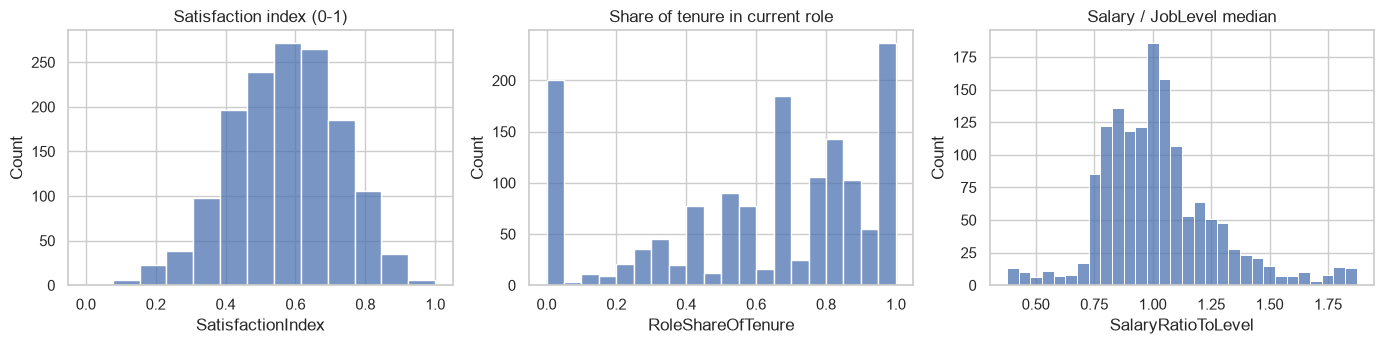

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(featured.SatisfactionIndex, bins=13, ax=axes[0]); axes[0].set_title("Satisfaction index (0-1)")
sns.histplot(featured.RoleShareOfTenure, bins=20, ax=axes[1]); axes[1].set_title("Share of tenure in current role")
sns.histplot(featured.SalaryRatioToLevel, bins=30, ax=axes[2]); axes[2].set_title("Salary / JobLevel median")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_engineered_features.png", dpi=150); plt.show()

## 4. Model feature set
What enters the model (Phase 5) and what is deliberately left out.

In [11]:
excluded = {
    "identifier": [ID_COL],
    "protected (audit only)": PROTECTED + ["AgeBand"],
    "undocumented rates": UNDOCUMENTED_RATE_COLS,
    "target / target-derived": ["Attrition", "AttritionFlag"],
    "duplicate encodings / reporting-only": ["OvertimeFlag", "TenureBand", "IncomeBand", "YearsSincePromotionBand",
                                              "SatisfactionIndex", "LowSatisfactionCount", "JobLevelMedianIncome",
                                              "SalaryRatioToLevel (recomputed in-pipeline)"],
}
for k, v in excluded.items():
    print(f"{k:38s} {v}")
print(f"\nModel numeric ({len(MODEL_NUMERIC)}) + SalaryRatioToLevel:", MODEL_NUMERIC)
print(f"Model categorical ({len(MODEL_CATEGORICAL)}):", MODEL_CATEGORICAL)
assert not set(PROTECTED) & set(MODEL_NUMERIC + MODEL_CATEGORICAL)

identifier                             ['EmployeeNumber']
protected (audit only)                 ['Age', 'Gender', 'MaritalStatus', 'AgeBand']
undocumented rates                     ['DailyRate', 'HourlyRate', 'MonthlyRate']
target / target-derived                ['Attrition', 'AttritionFlag']
duplicate encodings / reporting-only   ['OvertimeFlag', 'TenureBand', 'IncomeBand', 'YearsSincePromotionBand', 'SatisfactionIndex', 'LowSatisfactionCount', 'JobLevelMedianIncome', 'SalaryRatioToLevel (recomputed in-pipeline)']

Model numeric (20) + SalaryRatioToLevel: ['DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'RoleShareOfTenure']
Model categorical (5

## 5. Save outputs

In [12]:
(DATA / "processed").mkdir(parents=True, exist_ok=True)
cleaned.to_csv(DATA / "processed" / "hr_cleaned.csv", index=False)
featured.to_csv(DATA / "processed" / "hr_featured.csv", index=False)
print("hr_cleaned.csv ", cleaned.shape)
print("hr_featured.csv", featured.shape)

hr_cleaned.csv  (1470, 34)
hr_featured.csv (1470, 43)
